# code_023 · Capacity, overfitting and bias–variance

**Book:** section 5.2. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_05_GUIDE.md), [execution evidence](../CHAPTER_05_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_023). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=523;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 523


<a id="capacity"></a>
## Hold the data boundary fixed while varying capacity

Synthetic response in mm: f(x)=.4+1.1*x+.45*sin(pi*x), with x a fixed dimensionless coordinate uniform on [-1,1] and independent Gaussian noise sd .18 mm. Allocate 36 training, 120 development and 240 final independent members. Fit degrees 1,3,7,15 by unpenalized least squares in a Legendre basis on the declared coordinate. This basis improves conditioning but does not remove high-degree instability. Final targets are not used to select degree.

**Predict:** why can training error decrease when a column is added? Does an observed validation minimum have to be a universal U-shaped law?


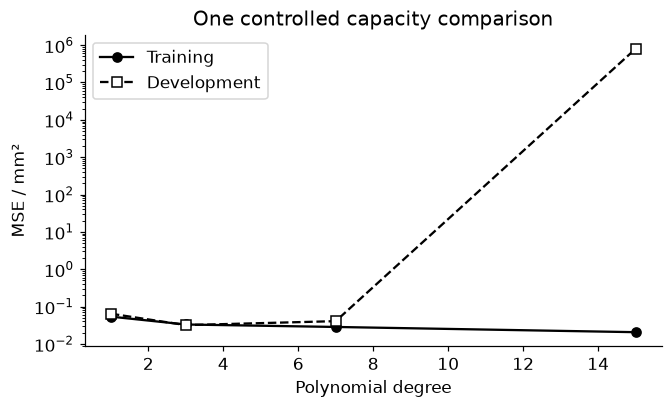

   degree  training_MSE_mm2  development_MSE_mm2
0       1          0.053792             0.064387
1       3          0.033104             0.031859
2       7          0.028436             0.040692
3      15          0.020603        796840.030915


In [2]:
from numpy.polynomial.legendre import legvander
truth=lambda x:.4+1.1*x+.45*np.sin(np.pi*x)
def design(x,d):return legvander(x,d)
def fit(x,y,d):return np.linalg.lstsq(design(x,d),y,rcond=None)[0]
x=rng.uniform(-1,1,396);y=truth(x)+rng.normal(0,.18,len(x));tr=np.arange(36);dv=np.arange(36,156);te=np.arange(156,396)
degrees=[1,3,7,15];weights=[fit(x[tr],y[tr],d) for d in degrees]
train_mse=[float(np.mean((design(x[tr],d)@w-y[tr])**2)) for d,w in zip(degrees,weights)]
dev_mse=[float(np.mean((design(x[dv],d)@w-y[dv])**2)) for d,w in zip(degrees,weights)]
chosen=int(np.argmin(dev_mse));selected=degrees[chosen]
assert not set(tr)&set(dv) and not set(tr)&set(te) and not set(dv)&set(te)
assert np.all(np.diff(train_mse)<=1e-10)
assert all(np.isfinite(train_mse+dev_mse)) and selected in degrees
fig,ax=plt.subplots(figsize=(6,3.6));ax.semilogy(degrees,train_mse,'ko-',label='Training');ax.semilogy(degrees,dev_mse,'ks--',mfc='white',label='Development')
ax.set(xlabel='Polynomial degree',ylabel='MSE / mm²',title='One controlled capacity comparison');ax.legend();plt.show()
print(pd.DataFrame({'degree':degrees,'training_MSE_mm2':train_mse,'development_MSE_mm2':dev_mse}))
RESULTS['degrees']=degrees;RESULTS['training_MSE_mm2']=train_mse;RESULTS['development_MSE_mm2']=dev_mse


<a id="final"></a>
## Assess the selected rule, once

The minimum development MSE selects a degree from four candidates. It is itself selected evidence, not an unbiased future-performance estimate. Freeze the chosen fitted coefficients, then open the independent final targets. Do not search seeds or degrees after reading this result.


In [3]:
final_mse=float(np.mean((design(x[te],selected)@weights[chosen]-y[te])**2))
assert len(te)==240 and np.isfinite(final_mse)
print('Selected degree:',selected,'final MSE [mm²]:',final_mse)
RESULTS['selected_degree']=selected;RESULTS['selected_final_MSE_mm2']=final_mse


Selected degree: 3 final MSE [mm²]: 0.03876894187667035


<a id="decomposition"></a>
## Repeated samples make prediction variability visible

This separate Monte Carlo experiment is not a second final evaluation. At fixed x0=.6, fit 250 independently generated training sets of 36 members at degrees 1,3,7. Variance uses population convention ddof=0 across fitted predictions. The finite-sample identity mean((prediction-f0)²)=(mean(prediction)-f0)²+mean((prediction-mean(prediction))²) is algebraically exact. Adding .18² gives the conditional expected error against a fresh independent zero-mean-noise response, averaged over these 250 fixed predictions. It is not a general decomposition for absolute error, accuracy or arbitrary losses.

**Predict:** does one training fit reveal variance over alternative training samples? Which independence and zero-mean assumptions remove the cross term?


,degree,bias_squared_mm2,prediction_variance_mm2,noise_variance_mm2,expected_fresh_noise_MSE_mm2
0,1,0.027492,0.004386,0.0324,0.064278
1,3,0.000312,0.003028,0.0324,0.035740
2,7,0.000153,0.007609,0.0324,0.040162


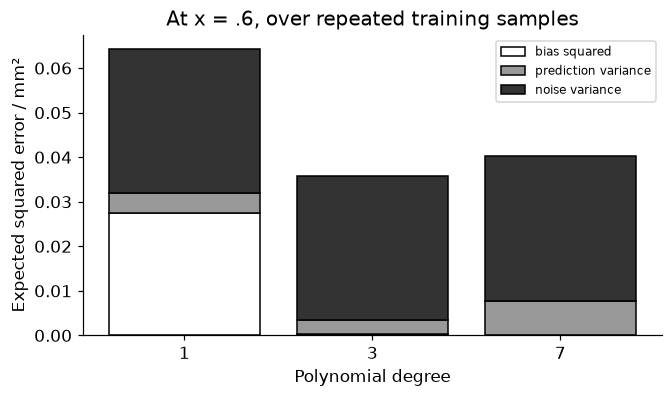

In [4]:
x0=.6;f0=float(truth(x0));predictions={};rows=[]
for d in [1,3,7]:
 values=[]
 for repeat in range(250):
  xx=rng.uniform(-1,1,36);yy=truth(xx)+rng.normal(0,.18,36)
  values.append(float((design(np.array([x0]),d)@fit(xx,yy,d))[0]))
 p=np.array(values);bias2=float((p.mean()-f0)**2);variance=float(np.mean((p-p.mean())**2));truth_error=float(np.mean((p-f0)**2))
 assert np.isclose(truth_error,bias2+variance,rtol=1e-10,atol=1e-12)
 assert variance>=0 and len(p)==250
 predictions[d]=p;rows.append([d,bias2,variance,.18**2,truth_error+.18**2])
table=pd.DataFrame(rows,columns=['degree','bias_squared_mm2','prediction_variance_mm2','noise_variance_mm2','expected_fresh_noise_MSE_mm2']);display(table)
fig,ax=plt.subplots(figsize=(6,3.5));positions=np.arange(3)
for col,style in [('bias_squared_mm2','white'),('prediction_variance_mm2','.6'),('noise_variance_mm2','.2')]:
 bottom=table[['bias_squared_mm2','prediction_variance_mm2','noise_variance_mm2']].loc[:,:col].iloc[:,:-1].sum(axis=1).to_numpy()
 ax.bar(positions,table[col],bottom=bottom,color=style,edgecolor='black',label=col.replace('_mm2','').replace('_',' '))
ax.set(xticks=positions,xticklabels=['1','3','7'],xlabel='Polynomial degree',ylabel='Expected squared error / mm²',title='At x = .6, over repeated training samples');ax.legend(fontsize=8);plt.show()
RESULTS['bias_variance_rows']=table.to_dict(orient='records')


<a id="exercises"></a>
## Exercises and hints

1. Repeat the decomposition at x=.95 and explain why an interior result need not describe the boundary.
2. Add an independently randomized training procedure. State whether you average over training samples, algorithm randomness or both.
3. Replace squared error with absolute error. Check why copying the same three-term algebra is invalid.
4. Repeat the whole development selection in a new simulated experiment. Record how often the selected degree changes, without choosing the most flattering seed.

**Hints:** flexibility, sample size, regularization and optimization jointly shape effective capacity. A U-shaped illustration is a possible pattern, not a theorem for all architectures or training regimes. See the official [bias–variance experiment](https://scikit-learn.org/1.9/auto_examples/ensemble/plot_bias_variance.html).


In [5]:
summary={'example_id':'code_023','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['controlled polynomial capacity curve', 'development-only degree selection', 'fresh final assessment', 'repeated-sample prediction variation', 'squared-error bias variance identity'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["controlled polynomial capacity curve", "development-only degree selection", "fresh final assessment", "repeated-sample prediction variation", "squared-error bias variance identity"], "elapsed_seconds": 0.298, "example_id": "code_023", "hardware": "Darwin arm64 CPU", "results": {"bias_variance_rows": [{"bias_squared_mm2": 0.027492361146237376, "degree": 1, "expected_fresh_noise_MSE_mm2": 0.06427822097971939, "noise_variance_mm2": 0.0324, "prediction_variance_mm2": 0.0043858598334819655}, {"bias_squared_mm2": 0.0003121990810495603, "degree": 3, "expected_fresh_noise_MSE_mm2": 0.03573988141627427, "noise_variance_mm2": 0.0324, "prediction_variance_mm2": 0.003027682335224716}, {"bias_squared_mm2": 0.00015260268032631717, "degree": 7, "expected_fresh_noise_MSE_mm2": 0.04016161864602079, "noise_variance_mm2": 0.0324, "prediction_variance_mm2": 0.007609015965694476}], "degrees": [1, 3, 7, 15], "development_MSE_mm2": [0.06438729522156877, 0.03